# 00 · Before and after: what preprocessing does to one trip

This notebook follows **one trip** from the raw files to the table the models will use. Every number
and plot below is computed from the raw files by the repo's own code (`src/pathsnap/`), and the
results are checked against the saved files in `data/processed/`. Nothing is typed in by hand.

| Step | Before | After |
|---|---|---|
| 1. Raw files | four text files | pandas tables |
| 2. Projection | longitude and latitude in degrees | x and y in metres |
| 3. Quality checks | raw GPS rows | the same rows (nothing is deleted) |
| 4. Labels | an ordered list of route arcs | one arc per GPS point |
| 5. Candidates | GPS points and a road network | one row per (GPS point, nearby road) |

Change `PART` and `TRIP` in the next cell to look at any train or student-test trip.

In [1]:
import os
from pathlib import Path
REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent
os.chdir(REPO)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import display

from pathsnap.io import discover_trips, load_trip
from pathsnap.geo import TripGeometry, haversine_m
from pathsnap.labels import align_route_to_observations
from pathsnap.candidates import generate_candidates, attach_labels

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})

PART, TRIP = "train", "00000072"      # a normal trip: 1 Hz, no gaps, no jumps
print("repo:", REPO)

repo: /Users/adyanthmallur/Downloads/PathSnap_student_materials/ML-Hackathon-148-2026


## 1. The raw files

Each trip is four header-less text files. Here are the first lines of each file exactly as stored,
then the same data as tables.

In [2]:
files = discover_trips(PART)[TRIP]
info = []
for kind in ("track", "nodes", "arcs", "route"):
    p = getattr(files, kind)
    with open(p) as fh:
        first = fh.readline().strip()
    info.append({"file": p.name, "size_kb": round(p.stat().st_size / 1024, 1),
                 "lines": sum(1 for _ in open(p)), "first line (raw text)": first})
display(pd.DataFrame(info))

,file,size_kb,lines,first line (raw text)
0,00000072.track,30.2,969,39.570730\t50.187493\t1.000000
1,00000072.nodes,64.0,3275,39.594177\t50.204729
2,00000072.arcs,63.9,7063,0\t326
3,00000072.route,0.6,131,6091


In [3]:
trip = load_trip(files, with_route=True)     # with_route=True: this is a train trip, labels are allowed
print("TRACK  (lon, lat in degrees; t in seconds)  shape", trip.track.shape)
display(trip.track.head(6))
print("NODES  (lon, lat; row number = node id)     shape", trip.nodes.shape)
display(trip.nodes.head(3))
print("ARCS   (from_node, to_node; row number = arc id)  shape", trip.arcs.shape)
display(trip.arcs.head(3))
print("ROUTE  (arc ids in driving order): first 12 of", len(trip.route))
print(trip.route[:12])

TRACK  (lon, lat in degrees; t in seconds)  shape (969, 3)


,lon,lat,t
obs_idx,,,
0,39.570730,50.187493,1.0
1,39.570591,50.187466,2.0
2,39.570648,50.187438,3.0
3,39.570497,50.187461,4.0
4,39.570409,50.187436,5.0
5,39.570314,50.187407,6.0


NODES  (lon, lat; row number = node id)     shape (3275, 2)


,lon,lat
node_id,,
0,39.594177,50.204729
1,39.592743,50.185229
2,39.568185,50.195623


ARCS   (from_node, to_node; row number = arc id)  shape (7063, 2)


,from_node,to_node
arc_id,,
0,0,326
1,0,1900
2,0,1647


ROUTE  (arc ids in driving order): first 12 of 131
[6091 6097 6095 4537 1352 3149 3153 3151 3147  344 4554 4542]


**Two things to notice.** The track has one row per GPS point, but the route is a list of *arcs* (road
segments). Nothing in the files says which GPS point belongs to which route arc, and the track and the
route have different lengths. Step 4 builds that link.

## 2. Projection: degrees to metres

Longitude and latitude are angles. One degree of longitude is a different distance depending on the
latitude, so distances computed on raw degrees are wrong. Each trip is projected into the UTM zone of its
own median point, which gives x and y in metres.

In [4]:
geom = TripGeometry.from_trip(trip)
print("UTM zone (EPSG code) chosen for this trip:", geom.proj.epsg)

before = trip.track[["lon", "lat"]].head(5).rename(columns={"lon": "lon (deg)", "lat": "lat (deg)"})
after = pd.DataFrame({"x (m)": geom.obs_x[:5], "y (m)": geom.obs_y[:5]})
print("BEFORE (degrees)   ->   AFTER (metres)")
display(pd.concat([before, after], axis=1))

UTM zone (EPSG code) chosen for this trip: 32637
BEFORE (degrees)   ->   AFTER (metres)


,lon (deg),lat (deg),x (m),y (m)
0,39.570730,50.187493,540743.137385,5.559633e+06
1,39.570591,50.187466,540733.237510,5.559630e+06
2,39.570648,50.187438,540737.330409,5.559627e+06
3,39.570497,50.187461,540726.531349,5.559630e+06
4,39.570409,50.187436,540720.270516,5.559627e+06


In [5]:
lon, lat = trip.track["lon"].to_numpy(), trip.track["lat"].to_numpy()
naive = np.hypot(np.diff(lon), np.diff(lat)) * 111_320            # pretend 1 degree = 111.32 km everywhere
projected = np.hypot(np.diff(geom.obs_x), np.diff(geom.obs_y))    # UTM metres
great_circle = haversine_m(lon[:-1], lat[:-1], lon[1:], lat[1:])  # reference: distance on the globe
cmp = pd.DataFrame({"naive degrees (m)": naive, "projected (m)": projected, "haversine (m)": great_circle})
print("Distance of each 1-second step, three ways (first rows):")
display(cmp.head(6).round(2))
print("Total GPS path length of the trip (m):")
display(cmp.sum().round(0).to_frame("total").T)

Distance of each 1-second step, three ways (first rows):


,naive degrees (m),projected (m),haversine (m)
0,15.76,10.37,10.34
1,7.07,5.12,5.11
2,17.00,11.08,11.05
3,10.18,6.87,6.85
4,11.06,7.51,7.49
5,13.35,8.66,8.63


Total GPS path length of the trip (m):


,naive degrees (m),projected (m),haversine (m)
total,14714.0,11311.0,11295.0


The projected distances agree with the great-circle distance. The naive version, which treats a degree
of longitude like a degree of latitude, is off. That is why all geometry in this project uses the
projected metres.

## 3. Quality checks: nothing is deleted

We check the GPS rows for problems, but we do not drop any rows. Problems are flagged and handled
later (the label alignment relaxes across gaps, outliers are flagged by distance to the road).

In [6]:
tr = trip.track
t = tr["t"].to_numpy()
dt = np.diff(t)
speed = projected / np.where(dt > 0, dt, np.nan)
checks = pd.Series({
    "GPS rows": len(tr),
    "rows with a missing value": int(tr.isna().any(axis=1).sum()),
    "longitude/latitude out of range": int(((tr.lon.abs() > 180) | (tr.lat.abs() > 90)).sum()),
    "(0, 0) coordinates": int(((tr.lon == 0) & (tr.lat == 0)).sum()),
    "timestamps strictly increasing": bool((dt > 0).all()),
    "steps that are exactly 1 s": f"{(dt == 1).mean():.1%}",
    "gaps longer than 5 s": int((dt > 5).sum()),
    "steps faster than 60 m/s": int(np.nansum(speed > 60)),
}).to_frame("this trip")
display(checks)
print(f"Rows before cleaning: {len(tr)}   rows after cleaning: {len(tr)}   (nothing removed)")

,this trip
GPS rows,969
rows with a missing value,0
longitude/latitude out of range,0
"(0, 0) coordinates",0
timestamps strictly increasing,True
steps that are exactly 1 s,100.0%
gaps longer than 5 s,0
steps faster than 60 m/s,0


Rows before cleaning: 969   rows after cleaning: 969   (nothing removed)


## 4. Labels: one road per GPS point

The route is an ordered list of arcs. We align every GPS point to one arc of that route with a dynamic
programme: the position along the route can never move backwards, the cost is the distance to the arc
(plus a penalty for driving against the arc's direction). The result is a derived label, not ground truth.

In [7]:
aligned = align_route_to_observations(geom, trip.route)
saved = pd.read_parquet(f"data/processed/labels/{PART}/{TRIP}.parquet")
same = (np.array_equal(aligned["arc_id"].to_numpy(), saved["arc_id"].to_numpy())
        and np.allclose(aligned["dist_m"].to_numpy(), saved["dist_m"].to_numpy(), atol=1e-3))
print("Recomputed labels identical to data/processed/labels file:", same)
print("BEFORE: route = list of arcs         ->  AFTER: one row per GPS point")
display(aligned.head(6).round(2))

summary = pd.Series({
    "GPS points labelled": len(aligned),
    "median distance to aligned arc (m)": round(float(aligned.dist_m.median()), 2),
    "95th percentile distance (m)": round(float(aligned.dist_m.quantile(0.95)), 2),
    "points flagged is_outlier (> 50 m)": int(aligned.is_outlier.sum()),
    "route arcs that received >= 1 point": f"{aligned.route_pos.nunique()} of {len(trip.route)}",
}).to_frame("this trip")
display(summary)

Recomputed labels identical to data/processed/labels file: True
BEFORE: route = list of arcs         ->  AFTER: one row per GPS point


,obs_idx,route_pos,arc_id,dist_m,is_outlier,after_gap
0,0,0,6091,15.64,False,False
1,1,0,6091,13.92,False,False
2,2,0,6091,18.52,False,False
3,3,0,6091,11.44,False,False
4,4,0,6091,11.14,False,False
5,5,0,6091,11.02,False,False


,this trip
GPS points labelled,969
median distance to aligned arc (m),5.74
95th percentile distance (m),13.97
points flagged is_outlier (> 50 m),0
route arcs that received >= 1 point,130 of 131


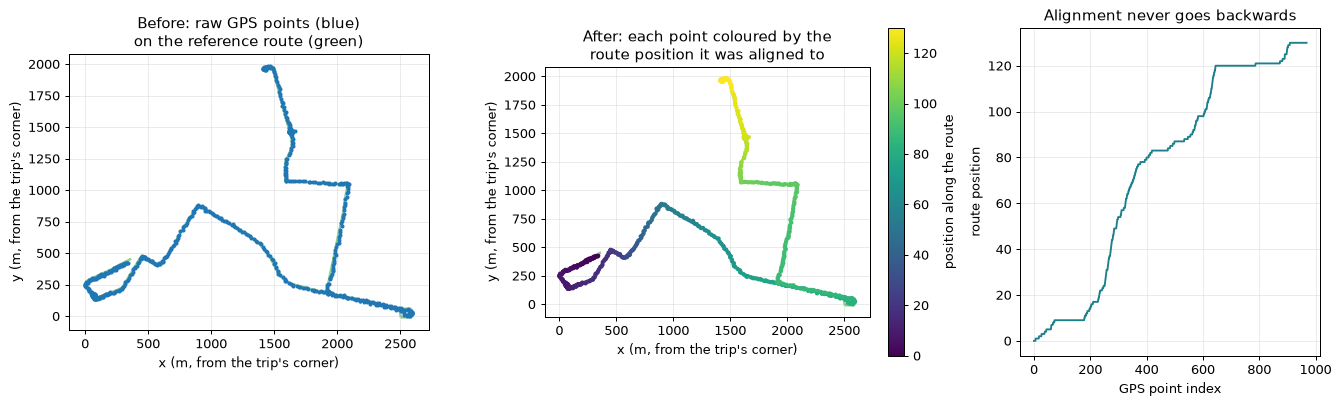

In [8]:
# plot in metres relative to the south-west corner of the trip (keeps the axis numbers small)
ox, oy = geom.obs_x.min(), geom.obs_y.min()
OX, OY = geom.obs_x - ox, geom.obs_y - oy
AX, AY, BX, BY = geom.ax - ox, geom.ay - oy, geom.bx - ox, geom.by - oy
r = trip.route
segs = np.stack([np.c_[AX[r], AY[r]], np.c_[BX[r], BY[r]]], axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
for ax in axes[:2]:
    ax.add_collection(LineCollection(segs, colors="#2ca02c", linewidths=2, alpha=0.5, zorder=1))
    ax.set_aspect("equal")
axes[0].scatter(OX, OY, s=5, color="#1f77b4", zorder=2)
axes[0].set_title("Before: raw GPS points (blue)\non the reference route (green)")
sc = axes[1].scatter(OX, OY, s=6, c=aligned.route_pos, cmap="viridis", zorder=2)
axes[1].set_title("After: each point coloured by the\nroute position it was aligned to")
plt.colorbar(sc, ax=axes[1], fraction=0.046, label="position along the route")
axes[2].plot(aligned.obs_idx, aligned.route_pos, color="#1b7f8c")
axes[2].set_xlabel("GPS point index")
axes[2].set_ylabel("route position")
axes[2].set_title("Alignment never goes backwards")
for ax in axes[:2]:
    ax.set_xlabel("x (m, from the trip's corner)")
    ax.set_ylabel("y (m, from the trip's corner)")
plt.tight_layout()
plt.show()

## 5. Candidates: which roads could each point be on?

For every GPS point we collect the road arcs within 60 m (at most 30, nearest first), using a spatial
index. The settings come from `configs/candidates.yaml` and were chosen from the miss-rate sweep on the
training trips. Each candidate row gets `label = 1` if it is the arc the point was aligned to, otherwise `0`.
This is the table the models score.

In [9]:
cands, no_candidates = generate_candidates(geom, TRIP)
cands = attach_labels(cands, aligned["arc_id"].to_numpy())
saved_c = pd.read_parquet(f"data/processed/candidates/{PART}/{TRIP}.parquet")
same_c = (len(cands) == len(saved_c)
          and np.array_equal(cands["arc_id"].to_numpy(), saved_c["arc_id"].to_numpy())
          and np.array_equal(cands["label"].to_numpy(), saved_c["label"].to_numpy()))
print("Recomputed candidates identical to data/processed/candidates file:", same_c)
print()
print("The candidate rows of the first two GPS points:")
display(cands[cands.obs_idx < 2].round(3))

Recomputed candidates identical to data/processed/candidates file: True

The candidate rows of the first two GPS points:


,trip_id,obs_idx,arc_id,dist_m,proj_frac,label
0,00000072,0,6091,15.637000,0.483,1
1,00000072,0,6096,15.637000,0.517,0
2,00000072,0,6090,38.619999,-0.853,0
3,00000072,0,6093,38.619999,1.853,0
4,00000072,0,6094,40.929001,1.594,0
5,00000072,0,6097,40.929001,-0.594,0
6,00000072,1,6091,13.922000,0.623,1
7,00000072,1,6096,13.922000,0.377,0
8,00000072,1,6094,30.912001,1.432,0
9,00000072,1,6097,30.912001,-0.432,0


Look at the first rows above. Many roads show up **twice with the same `dist_m`**: a two-way street is
two arcs with identical geometry, one per direction. `proj_frac` is mirrored for such a pair. Distance
alone cannot tell them apart, which is why the features will include the GPS heading against the arc
direction.

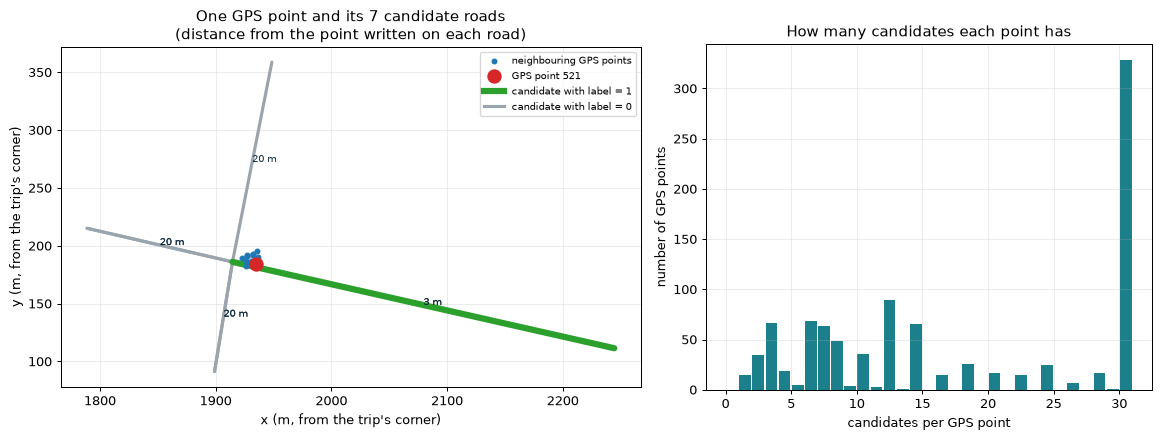

,trip_id,obs_idx,arc_id,dist_m,proj_frac,label
0,00000072,521,3,2.590000,0.060,0
1,00000072,521,276,2.590000,0.940,1
2,00000072,521,5,20.356001,0.012,0
3,00000072,521,4,20.455999,-0.157,0
4,00000072,521,6,20.455999,-0.014,0
5,00000072,521,95,20.455999,1.014,0
6,00000072,521,722,20.455999,1.157,0


In [10]:
counts = cands.groupby("obs_idx").size()
has_pos = cands.groupby("obs_idx")["label"].max()
eligible = counts[(counts >= 6) & (has_pos == 1)].index
i = int(eligible[len(eligible) // 2])           # a representative point from the middle of the trip
rows = cands[cands.obs_idx == i]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for rw in rows.itertuples():
    a = rw.arc_id
    pos = rw.label == 1
    ax.plot([AX[a], BX[a]], [AY[a], BY[a]], color="#2ca02c" if pos else "#9aa4ad",
            lw=5 if pos else 2.5, solid_capstyle="round", zorder=2 if pos else 1)
    ax.annotate(f"{rw.dist_m:.0f} m", ((AX[a] + BX[a]) / 2, (AY[a] + BY[a]) / 2), fontsize=8,
                color="#0f2b3d", zorder=4)
nb = slice(max(0, i - 6), i + 7)
ax.plot(OX[nb], OY[nb], "-", color="#1f77b4", alpha=0.4)
ax.scatter(OX[nb], OY[nb], s=14, color="#1f77b4", zorder=3, label="neighbouring GPS points")
ax.scatter(OX[i], OY[i], s=110, color="#d62728", zorder=5, label=f"GPS point {i}")
ax.plot([], [], color="#2ca02c", lw=5, label="candidate with label = 1")
ax.plot([], [], color="#9aa4ad", lw=2.5, label="candidate with label = 0")
ax.set_aspect("equal")
ax.set_xlabel("x (m, from the trip's corner)")
ax.set_ylabel("y (m, from the trip's corner)")
ax.set_title(f"One GPS point and its {len(rows)} candidate roads\n(distance from the point written on each road)")
ax.legend(fontsize=8, loc="best")

axes[1].hist(counts, bins=range(0, int(counts.max()) + 2), color="#1b7f8c", rwidth=0.9)
axes[1].set_xlabel("candidates per GPS point")
axes[1].set_ylabel("number of GPS points")
axes[1].set_title("How many candidates each point has")
plt.tight_layout()
plt.show()
display(rows.round(3).reset_index(drop=True))

**Reading the figure and the table above.**
- The green road is the one the point was aligned to (`label = 1`); the grey roads are the other candidates, with
  their distance written on them.
- If two rows in the table have exactly the same `dist_m`, they are **twin arcs** (the same street in opposite
  directions) and they are drawn on top of each other. Only one of them is the labelled direction.
- In the histogram, the bar at the right edge is the number of points that reached the cap of 30 candidates.
  Those points sit in dense parts of the network (junctions, parallel streets), where the cap `K` is what limits the list.

## 6. From raw points to the model table: the counts

The same trip, followed through the whole preprocessing.

In [11]:
n_obs = len(trip.track)
obs_with_cands = cands["obs_idx"].nunique()
pos = int((cands.label == 1).sum())
funnel = pd.DataFrame([
    ("GPS points in the raw file", n_obs),
    ("GPS points with at least one candidate road", obs_with_cands),
    ("candidate rows (the table the model sees)", len(cands)),
    ("  of which label = 1 (the aligned road)", pos),
    ("  of which label = 0", len(cands) - pos),
    ("GPS points whose aligned road is not among the candidates", n_obs - int(has_pos.sum())),
    ("GPS points flagged is_outlier", int(aligned.is_outlier.sum())),
], columns=["stage", "count"])
display(funnel)
print(f"Average candidates per GPS point: {len(cands) / obs_with_cands:.2f}")
print(f"Share of candidate rows that are positive: {pos / len(cands):.1%}  (so accuracy alone would be misleading)")

,stage,count
0,GPS points in the raw file,969
1,GPS points with at least one candidate road,969
2,candidate rows (the table the model sees),16550
3,of which label = 1 (the aligned road),968
4,of which label = 0,15582
5,GPS points whose aligned road is not among the...,1
6,GPS points flagged is_outlier,0


Average candidates per GPS point: 17.08
Share of candidate rows that are positive: 5.8%  (so accuracy alone would be misleading)


## What the models receive next

| Input | Output |
|---|---|
| `data/processed/candidates/<partition>/<trip>.parquet` with `trip_id, obs_idx, arc_id, dist_m, proj_frac, label` | feature engineering adds distance, direction, context, motion and network features to this table |

Candidate rows are scored by the classifier. The HMM and Viterbi decoder then uses road connectivity to
turn those scores into one connected route.